# Fire event AOIs

Boxes from `config/events.toml`; vector files from `data/reference/aoi/`.

In [47]:
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt

from vifdahl.events import load_events

AOI_DIR = Path("../data/reference/aoi")
#MAP_CRS = ccrs.epsg(3338)
MAP_CRS = ccrs.LambertAzimuthalEqualArea(
    central_latitude=90, central_longitude=-150)
EXTENT = (-170, -110, 55, 71)  # lon/lat

In [48]:
events = load_events()
boxes = gpd.GeoDataFrame(
    {"key": list(events), "name": [e.name for e in events.values()],
     "start": [e.start for e in events.values()]},
    geometry=[e.aoi() for e in events.values()], crs="EPSG:4326",
)
boxes

,key,name,start,geometry
0,sockeye,Sockeye Fire,2015-06-13,"POLYGON ((-149.89639 61.71013, -149.89633 61.7..."
1,eagle,Eagle Fire,2015-05-26,"POLYGON ((-139.97676 63.20561, -139.97657 63.2..."
2,shovelcreek,Shovel Creek Fire,2019-06-24,"POLYGON ((-147.99296 64.89665, -147.99282 64.9..."
3,blackriver,Calkyitsik Complex,2019-06-23,"POLYGON ((-142.39168 66.13047, -142.39137 66.1..."
4,hesscreek,Hess Creek Fire,None,"POLYGON ((-147.293 65.15725, -147.29264 65.166..."
5,swanlake,Swan Lake Fire,2019-07-10,"POLYGON ((-149.89347 60.40507, -149.89332 60.4..."
6,nuggetcreek,Nugget Creek Fire,2019-06-24,"POLYGON ((-146.24131 64.66734, -146.2412 64.67..."
7,mckinley,McKinley Fire,2019-08-18,"POLYGON ((-149.82088 61.89279, -149.82082 61.9..."
8,deshka,Deshka Landing Fire,2019-08-18,"POLYGON ((-150.04406 61.63053, -150.04402 61.6..."
9,northfork,North Fork Fire,None,"POLYGON ((-151.52738 59.64948, -151.52734 59.6..."


In [49]:
aoi_files = sorted(p for p in AOI_DIR.iterdir() if p.suffix in {".geojson", ".json", ".shp"})
aoi_files

[PosixPath('../data/reference/aoi/BorealAKForUAFSmoke.json'),
 PosixPath('../data/reference/aoi/FireROI_forGINAVIIRS.geojson'),
 PosixPath('../data/reference/aoi/alaska.json')]

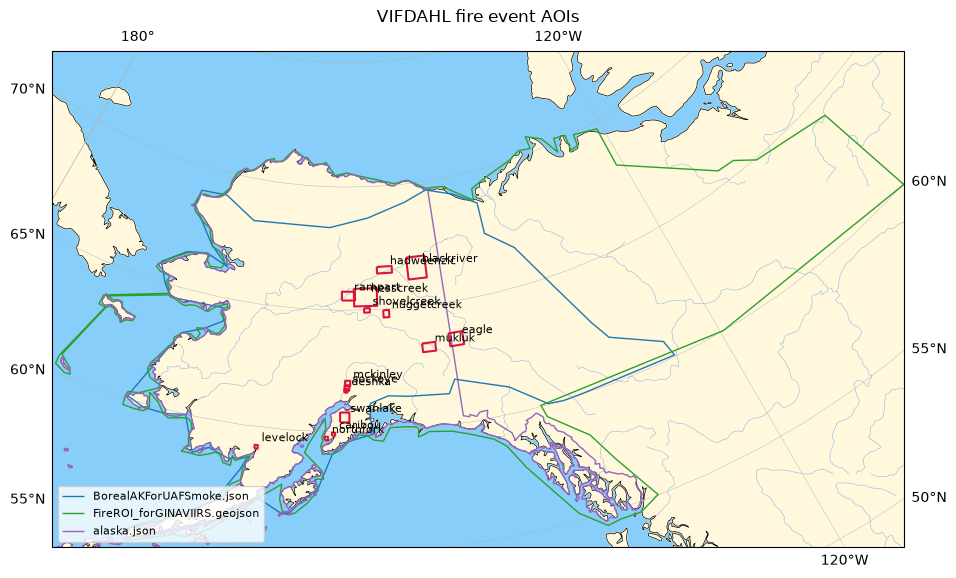

In [51]:
fig, ax = plt.subplots(figsize=(11, 9), subplot_kw={"projection": MAP_CRS})
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
ax.set_facecolor("lightskyblue")
ax.add_feature(cfeature.LAND, color="cornsilk")
# ax.add_feature(cfeature.OCEAN, color="lightskyblue")
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.RIVERS, linewidth=0.4)
ax.gridlines(draw_labels=True, linewidth=0.3)

for path, color in zip(aoi_files, ["tab:blue", "tab:green", "tab:purple", "tab:gray"]):
    gdf = gpd.read_file(path).to_crs(MAP_CRS.proj4_init)
    gdf.boundary.plot(ax=ax, color=color, linewidth=1, label=path.name)

boxes.to_crs(MAP_CRS.proj4_init).boundary.plot(ax=ax, color="crimson", linewidth=1.5)
for _, row in boxes.to_crs(MAP_CRS.proj4_init).iterrows():
    x, y = row.geometry.centroid.coords[0]
    ax.annotate(row["key"], (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.legend(loc="lower left", fontsize=8)
ax.set_title("VIFDAHL fire event AOIs");